In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random
import time
%matplotlib inline

SEED = 2147483647
g = torch.Generator().manual_seed(SEED)

In [53]:
class Linear:
  def __init__(self, fan_in, fan_out, bias=True):
    self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5
    self.bias = torch.zeros(fan_out) if bias else None

  def __call__(self, x):
    self.out = x @ self.weight
    if self.bias is not None:
      self.out = self.out + self.bias
    return self.out

  def parameters(self):
    return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1d:
  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True
    # parameters trained with backprop
    self.gamma = torch.ones(dim)
    self.beta = torch.zeros(dim)
    # buffer trained with a running momentum update not backprop
    self.running_mean = torch.zeros(dim)
    self.running_var = torch.ones(dim)

  def __call__(self, x):
    if self.training:
      if x.ndim==2:
        dim = 0
      elif x.ndim==3:  #we assume c is the last layer, so we want to average over the first two dimensions (batch and time)
        dim = (0,1)
      xmean = x.mean(dim, keepdim=True)  #batch mean
      xvar = x.var(dim, keepdim=True, unbiased=True)  #batch variance
    else:
      xmean = self.running_mean
      xvar = self.running_var
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps) #unit variance
    self.out = self.gamma * xhat + self.beta
    if self.training:
      with torch.no_grad():
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean #update buffer
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
    return self.out

  def parameters(self):
    return [self.gamma, self.beta]


class Tanh:
  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out

  def parameters(self):
    return []


class Embedding:
  def __init__(self, num_embeddings, embedding_dim):
    self.weight = torch.randn((num_embeddings, embedding_dim))
    
  def __call__(self, IX):
    self.out = self.weight[IX]
    return self.out
  
  def parameters(self):
    return [self.weight]

class Flatten:
  def __call__(self, x):
    self.out = x.view(x.shape[0], -1)
    return self.out
  
  def parameters(self):
    return []

class FlattenConsecutive:
  def __init__(self, n):
    self.n = n
    
  def __call__(self, x):
    B, T, C = x.shape #4 8 10
    x = x.view(B, T//self.n, C*self.n)
    if x.shape[1] == 1:
      x = x.squeeze(1)
    self.out = x
    return self.out
  
  def parameters(self):
    return []

class Sequential:
  def __init__(self, layers):
    self.layers = layers
  
  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    self.out = x
    return self.out
  
  def parameters(self):
    # get parameters of all layers and stretch them out into one list
    return [p for layer in self.layers for p in layer.parameters()]

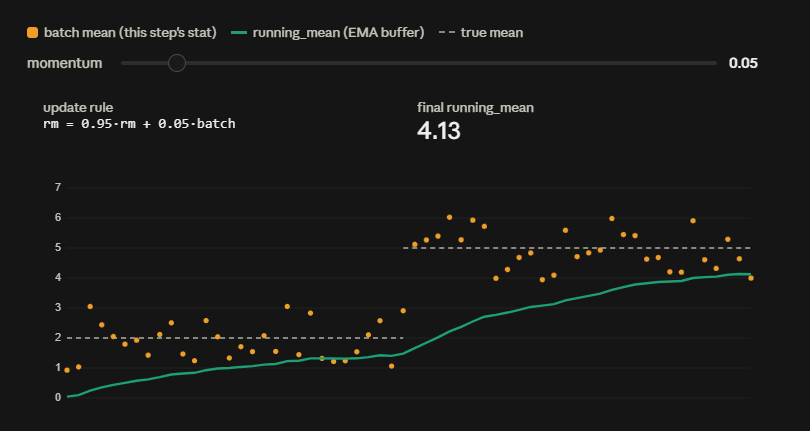 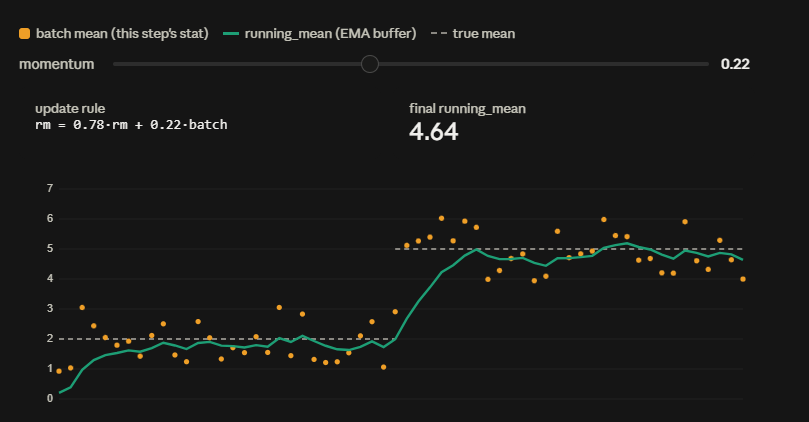

during trainings use batch stats and update deterministic general mean and var. At inference time use this stats to acquire deterministic results--> using stats of one batch will be noisy

In [54]:
words = open('names.txt', 'r').read().splitlines()
chars = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [55]:
import random
random.seed(42)
random.shuffle(words)

In [56]:
# build the dataset
block_size = 8 # context length

def build_dataset(words):  
  X, Y = [], []
  
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] 

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
Xtr,  Ytr  = build_dataset(words[:n1])    
Xdev, Ydev = build_dataset(words[n1:n2])   
Xte,  Yte  = build_dataset(words[n2:])    

torch.Size([182625, 8]) torch.Size([182625])
torch.Size([22655, 8]) torch.Size([22655])
torch.Size([22866, 8]) torch.Size([22866])


In [57]:
for x,y in zip(Xtr[:20], Ytr[:20]):
  print(''.join(itos[ix.item()] for ix in x), '-->', itos[y.item()])

........ --> y
.......y --> u
......yu --> h
.....yuh --> e
....yuhe --> n
...yuhen --> g
..yuheng --> .
........ --> d
.......d --> i
......di --> o
.....dio --> n
....dion --> d
...diond --> r
..diondr --> e
.diondre --> .
........ --> x
.......x --> a
......xa --> v
.....xav --> i
....xavi --> e


In [32]:
torch.manual_seed(42); # seed rng for reproducibility

In [68]:
n_embd = 24 # the dimensionality of the character embedding vectors
n_hidden = 128 # the number of neurons in the hidden layer of the MLP

model = Sequential([
  Embedding(vocab_size, n_embd),  
  FlattenConsecutive(2), Linear(n_embd * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(n_hidden, vocab_size)
])
# parameter init
with torch.no_grad():
  model.layers[-1].weight *= 0.1 # last layer make less confident

parameters = model.parameters()
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

76579


In [59]:
ix = torch.randint(0, Xtr.shape[0], (4,))
Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
logits = model(Xb)
print(Xb.shape)
Xb

torch.Size([4, 8])


tensor([[ 0,  0,  0,  0,  0,  0, 18, 21],
        [ 0,  0,  0,  0,  0,  0,  0,  1],
        [ 0,  0,  0,  0,  1, 14,  4, 18],
        [ 0,  0,  0,  0,  0,  0,  0,  1]])

In [60]:
model.layers[3].running_mean.shape

torch.Size([1, 1, 68])

flattenconsecutive(8) : <br>
Embedding : (4, 8, 10)
FlattenConsecutive : (4, 80)
Linear : (4, 200)
BatchNorm1d : (4, 200)
Tanh : (4, 200)
Linear : (4, 27)

In [70]:
for layer in model.layers:
    print(layer.__class__.__name__, ':', tuple(layer.out.shape))

Embedding : (32, 8, 24)
FlattenConsecutive : (32, 4, 48)
Linear : (32, 4, 128)
BatchNorm1d : (32, 4, 128)
Tanh : (32, 4, 128)
FlattenConsecutive : (32, 2, 256)
Linear : (32, 2, 128)
BatchNorm1d : (32, 2, 128)
Tanh : (32, 2, 128)
FlattenConsecutive : (32, 256)
Linear : (32, 128)
BatchNorm1d : (32, 128)
Tanh : (32, 128)
Linear : (32, 27)


In [69]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,))
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

  logits = model(Xb)
  loss = F.cross_entropy(logits, Yb) # loss function
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update: simple SGD
  lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.2867
  10000/ 200000: 2.0463
  20000/ 200000: 1.8193
  30000/ 200000: 1.8612
  40000/ 200000: 2.2444
  50000/ 200000: 1.9150
  60000/ 200000: 2.1825
  70000/ 200000: 2.0361
  80000/ 200000: 2.2228
  90000/ 200000: 1.9995
 100000/ 200000: 1.6801
 110000/ 200000: 1.9044
 120000/ 200000: 1.8143
 130000/ 200000: 1.8438
 140000/ 200000: 2.1049
 150000/ 200000: 1.4746
 160000/ 200000: 1.6454
 170000/ 200000: 2.0542
 180000/ 200000: 1.9180
 190000/ 200000: 1.8305


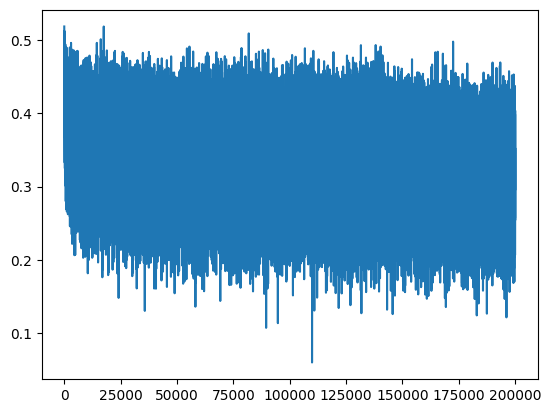

In [12]:
plt.plot(lossi)

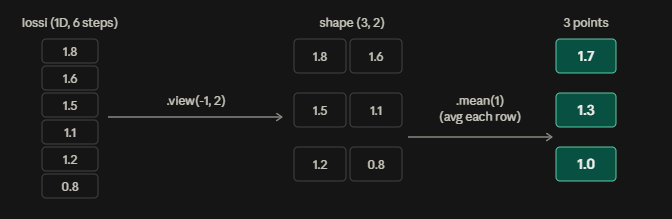

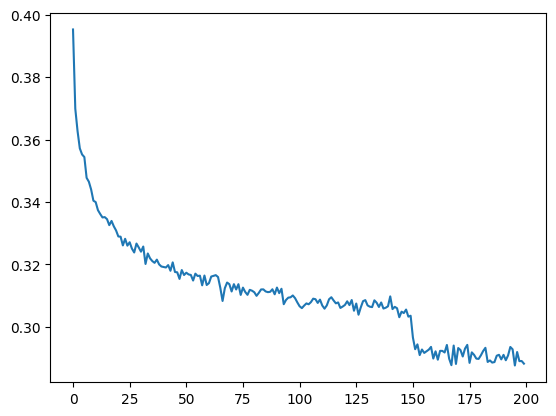

In [35]:
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))

In [71]:
for layer in model.layers:
    layer.training = False

In [72]:
@torch.no_grad()
def split_loss(split):
    x, y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test': (Xte, Yte),
    }[split]
    
    logits=model(x)
    loss = F.cross_entropy(logits, y) # loss function
    print(f'{split} loss: {loss.item():.4f}')

split_loss('train')
split_loss('val')

train loss: 1.7730
val loss: 1.9953


before fixing batchnorm: train loss: 1.9409 val loss: 2.0236 <br>
after fixing: train loss: 1.9108 val loss: 2.0129 --> it didnt change so much because we are just calculating stats with considering more numbers<br>
scale up parameters: 76579 train loss: 1.7730 val loss: 1.9953

***3 letter context size --> train loss: 2.0595 val loss: 2.1055 parameters: 12097 <br>
***names for 3 letter -->
gur.
elsiah.
saya.
vaitler.
tok.
staphrise.
sma.
joyle.
kidhiolle.
nia.
markera.
hilandrezodimy.
mylender.
zakshice.
rick.
raiderid.
maria.
noi.
navi.
coralee.<br>
********8 letter context size --> train loss: 1.9194
val loss: 2.0285 paramters: 22097<br>
********names for 8 letter --> harzal.
hasho.
atyla.
evan.
rubi.
demarila.
adil.
ellerah.
jansen.
maryahne.
kalaya.
darry.
stelanna.
kustine.
olani.
lonte.
adralynn.
aianna.
jeramarr.
zyrian

In [73]:
for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        logits = model(torch.tensor([context]))
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix] # context window shifting
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[i] for i in out))

ameri.
syrina.
merni.
malamii.
elyden.
johnni.
annai.
anai.
tritten.
denyx.
azriel.
gweng.
cornelle.
anasra.
conner.
alandra.
chanlee.
yulian.
folnna.
chrissa.


Türkçe

In [74]:
words_tr = open('turkish_names.txt', 'r', encoding='utf-8').read().splitlines()
chars_tr = sorted(list(set(''.join(words_tr))))
stoi_tr = {s: i+1 for i, s in enumerate(chars_tr)}
stoi_tr['.'] = 0
itos_tr = {i: s for s, i in stoi_tr.items()}
vocab_size_tr = len(itos_tr)
print(itos_tr)
print(vocab_size_tr)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'r', 18: 's', 19: 't', 20: 'u', 21: 'v', 22: 'y', 23: 'z', 24: 'ç', 25: 'ö', 26: 'ü', 27: 'ğ', 28: 'ı', 29: 'ş', 0: '.'}
30


In [79]:
# build the dataset
block_size = 8 # context length

def build_dataset_tr(words_tr):  
    X, Y = [], []
    
    for w in words_tr:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi_tr[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

n1tr = int(0.8 * len(words_tr))
n2tr = int(0.9 * len(words_tr))


Xtr_tr, Ytr_tr = build_dataset_tr(words_tr[:n1tr])
Xdev_tr, Ydev_tr = build_dataset_tr(words_tr[n1tr:n2tr])
Xte_tr, Yte_tr = build_dataset_tr(words_tr[n2:])

torch.Size([57832, 8]) torch.Size([57832])
torch.Size([7280, 8]) torch.Size([7280])
torch.Size([7196, 8]) torch.Size([7196])


In [80]:
n_embd = 24 # the dimensionality of the character embedding vectors
n_hidden = 128 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(42)

model_tr = Sequential([
  Embedding(vocab_size, n_embd),  
  FlattenConsecutive(2), Linear(n_embd * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(n_hidden, vocab_size)
])
# parameter init
with torch.no_grad():
  model_tr.layers[-1].weight *= 0.1 # last layer make less confident

parameters = model_tr.parameters()
print(sum(p.nelement() for p in model_tr.parameters())) # number of parameters in total
for p in model_tr.parameters():
  p.requires_grad = True

76579


In [ ]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr_tr.shape[0], (batch_size,))
  Xb, Yb = Xtr_tr[ix], Ytr_tr[ix] # batch X,Y

model_tr = Sequential([
    Embedding(vocab_size_tr, n_embd),
    FlattenConsecutive(2), Linear(n_embd * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    FlattenConsecutive(2), Linear(n_hidden * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size_tr)
])
  loss = F.cross_entropy(logits, Yb) # loss function
  
  # backward pass
  for p in model_tr.parameters():
    p.grad = None
  loss.backward()
  
  # update: simple SGD
  lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
  for p in model_tr.parameters():
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

IndexError: index 29 is out of bounds for dimension 0 with size 27

In [ ]:
val_wave_tr = split_loss(model_wave_tr, 'val', splits_tr)
print('train:', split_loss(model_wave_tr, 'train', splits_tr))
print('val  :', val_wave_tr)
print()
week4_turkish_val = 2.1148674488067627
print(f'hafta 4 Turkce MLP (context 3)  val loss: {week4_turkish_val:.4f}')
print(f'hafta 6 Turkce WaveNet (context 8) val loss: {val_wave_tr:.4f}')
print(f'fark: {val_wave_tr - week4_turkish_val:+.4f}')

In [ ]:
def generate_tr(model, block_size, n=20, seed=SEED + 10):
  gg = torch.Generator().manual_seed(seed)
  model.eval()
  names = []
  for _ in range(n):
    out = []
    context = [0] * block_size
    while True:
      logits = model(torch.tensor([context]))
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=gg).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    names.append(''.join(itos_tr[i] for i in out[:-1]))
  model.train()
  return names

for name in generate_tr(model_wave_tr, block_size):
  print(name)

**Türkçe'de bağlamı 8'e çıkarmanın kazandırdığı** *(sayılar bir üstteki hücreden okunuyor)*

## 8. Bonus (b): konfigürasyon listesinden deney düzeneği

Her konfigürasyonu elle yazıp çalıştırmak yerine, `(mimari, block_size, n_embd, n_hidden, adim)` içeren bir konfig listesi tanımlayıp döngüyle eğitip sonucu tabloya yazan küçük bir düzenek. Kıyaslanabilir kalması için tüm konfigler burada daha küçük bir adım bütçesiyle (15000) çalışıyor — amaç en iyi sayıyı bulmak değil, deney düzeneğinin kendisi.

In [ ]:
def build_model(arch, block_size, n_embd, n_hidden, vsize):
  global g
  g = torch.Generator().manual_seed(SEED)
  if arch == 'flat':
    layers = [Embedding(vsize, n_embd), Flatten(),
              Linear(n_embd * block_size, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
              Linear(n_hidden, vsize)]
  elif arch == 'wavenet':
    layers = [Embedding(vsize, n_embd)]
    t = block_size
    fan_in = n_embd
    while t > 1:
      layers += [FlattenConsecutive(2), Linear(fan_in * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh()]
      fan_in = n_hidden
      t //= 2
    layers += [Linear(n_hidden, vsize)]
  model = Sequential(layers)
  with torch.no_grad():
    model.layers[-1].weight *= 0.1
  for p in model.parameters():
    p.requires_grad = True
  return model


def run_config(cfg):
  block_size = cfg['block_size']
  splits = splits3 if block_size == 3 else splits8
  model = build_model(cfg['arch'], block_size, cfg['n_embd'], cfg['n_hidden'], vocab_size)
  train(model, splits, max_steps=cfg['steps'], log_every=cfg['steps'] + 1)
  nparams = sum(p.nelement() for p in model.parameters())
  val = split_loss(model, 'val', splits)
  return nparams, val


configs = [
  {'arch': 'flat',    'block_size': 3, 'n_embd': 10, 'n_hidden': 200, 'steps': 15000},
  {'arch': 'flat',    'block_size': 8, 'n_embd': 10, 'n_hidden': 200, 'steps': 15000},
  {'arch': 'wavenet', 'block_size': 8, 'n_embd': 10, 'n_hidden': 68,  'steps': 15000},
  {'arch': 'wavenet', 'block_size': 8, 'n_embd': 24, 'n_hidden': 128, 'steps': 15000},
  {'arch': 'wavenet', 'block_size': 8, 'n_embd': 32, 'n_hidden': 160, 'steps': 15000},
]

print(f"{'arch':<9}{'block':>6}{'n_embd':>8}{'n_hidden':>10}{'steps':>8}{'params':>10}{'val':>9}")
results = []
for cfg in configs:
  nparams, val = run_config(cfg)
  results.append((cfg, nparams, val))
  print(f"{cfg['arch']:<9}{cfg['block_size']:>6}{cfg['n_embd']:>8}{cfg['n_hidden']:>10}{cfg['steps']:>8}{nparams:>10}{val:>9.4f}")

**Not:** sweep'teki en iyi val loss, Karpathy'nin videoda ulaştığı ~1.99 seviyesiyle kıyaslanabilir bir referans veriyor (bkz. görev 7c: "kendi loss'unu geçmeye çağırıyor"). Burada amaç 15000 adımlık kısıtlı bütçede mimarinin/boyutun etkisini görmek; adım sayısını 40000+'a çıkarmak (yukarıdaki bölümlerdeki gibi) sayıyı daha da iyileştirir.